# Ex 8 — Recommender System

**Content-based filtering with TF-IDF and cosine similarity**  
**Data:** productivity apps (S.No 20)  
**Reg No:** URK24CS1021

In [1]:
print("URK24CS1021")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

productivity_apps_data = {
    'app_name': [
        'Todoist', 'Evernote', 'Forest', 'Toggl Track', 'Google Keep',
        'Microsoft To Do', 'Focus Keeper', 'Notion', 'RescueTime', 'Habitica'
    ],
    'description': [
        'Task management app with projects, labels, and due dates for organizing work',
        'Note-taking app that syncs across devices with web clipping and organization',
        'Focus timer that grows virtual trees when you avoid using your phone',
        'Time tracking tool for monitoring how you spend time on different activities',
        'Simple note-taking service with color coding, labels, and checklist features',
        'Task management app with smart suggestions and integration with Office 365',
        'Pomodoro timer that uses 25-minute work sessions with short breaks',
        'All-in-one workspace for notes, tasks, databases, and collaborative work',
        'Automatic time tracking that shows how you spend time on websites and apps',
        'Gamified habit-building app that turns tasks into RPG game elements'
    ],
    'function': [
        'Task Management, Organization, Productivity',
        'Note-taking, Organization, Sync',
        'Focus, Time Management, Gamification',
        'Time Tracking, Analytics, Productivity',
        'Quick Notes, Checklists, Simple',
        'Task Management, Microsoft Integration',
        'Pomodoro Technique, Focus, Timer',
        'All-in-one, Workspace, Collaboration',
        'Automatic Tracking, Analytics, Focus',
        'Gamification, Habits, Motivation'
    ]
}

apps = pd.DataFrame(productivity_apps_data)
apps

URK24CS1021


,app_name,description,function
0,Todoist,"Task management app with projects, labels, a...","Task Management, Organization, Productivity"
1,Evernote,Note-taking app that syncs across devices wi...,"Note-taking, Organization, Sync"
2,Forest,Focus timer that grows virtual trees when yo...,"Focus, Time Management, Gamification"
3,Toggl Track,Time tracking tool for monitoring how you sp...,"Time Tracking, Analytics, Productivity"
4,Google Keep,Simple note-taking service with color coding...,"Quick Notes, Checklists, Simple"
5,Microsoft To Do,Task management app with smart suggestions a...,"Task Management, Microsoft Integration"
6,Focus Keeper,Pomodoro timer that uses 25-minute work sess...,"Pomodoro Technique, Focus, Timer"
7,Notion,"All-in-one workspace for notes, tasks, datab...","All-in-one, Workspace, Collaboration"
8,RescueTime,Automatic time tracking that shows how you s...,"Automatic Tracking, Analytics, Focus"
9,Habitica,Gamified habit-building app that turns tasks...,"Gamification, Habits, Motivation"


### One text field per app

In [2]:
print("URK24CS1021")

# lowercase so Focus and focus are the same word
apps["combined"] = (apps["description"] + " " + apps["function"]).str.lower()
apps.loc[6, "combined"]

URK24CS1021


'pomodoro timer that uses 25-minute work sessions with short breaks pomodoro technique, focus, timer'

### Text to numbers: TF-IDF

In [3]:
print("URK24CS1021")

# common words get a low weight, words only one app uses get a high one
tfidf = TfidfVectorizer(stop_words="english")
matrix = tfidf.fit_transform(apps["combined"])
matrix.shape

URK24CS1021


(10, 75)

In [4]:
print("URK24CS1021")

words = tfidf.get_feature_names_out()
row = pd.Series(matrix[6].toarray()[0], index=words)
row.sort_values(ascending=False).head(5)

URK24CS1021


pomodoro    0.516451
timer       0.439031
25          0.258226
sessions    0.258226
uses        0.258226
dtype: float64

### How close is every app to every other app?

In [5]:
print("URK24CS1021")

sim = cosine_similarity(matrix)
sim_df = pd.DataFrame(sim, index=apps["app_name"], columns=apps["app_name"])
sim_df.round(2)

URK24CS1021


app_name,Todoist,Evernote,Forest,Toggl Track,Google Keep,Microsoft To Do,Focus Keeper,Notion,RescueTime,Habitica
app_name,,,,,,,,,,
Todoist,1.00,0.15,0.10,0.06,0.06,0.43,0.04,0.05,0.00,0.04
Evernote,0.15,1.00,0.00,0.00,0.21,0.03,0.00,0.00,0.00,0.04
Forest,0.10,0.00,1.00,0.13,0.00,0.09,0.20,0.00,0.18,0.07
Toggl Track,0.06,0.00,0.13,1.00,0.00,0.00,0.00,0.00,0.54,0.00
Google Keep,0.06,0.21,0.00,0.00,1.00,0.00,0.00,0.06,0.00,0.00
Microsoft To Do,0.43,0.03,0.09,0.00,0.00,1.00,0.00,0.00,0.00,0.03
Focus Keeper,0.04,0.00,0.20,0.00,0.00,0.00,1.00,0.05,0.04,0.00
Notion,0.05,0.00,0.00,0.00,0.06,0.00,0.05,1.00,0.00,0.07
RescueTime,0.00,0.00,0.18,0.54,0.00,0.00,0.04,0.00,1.00,0.00


URK24CS1021


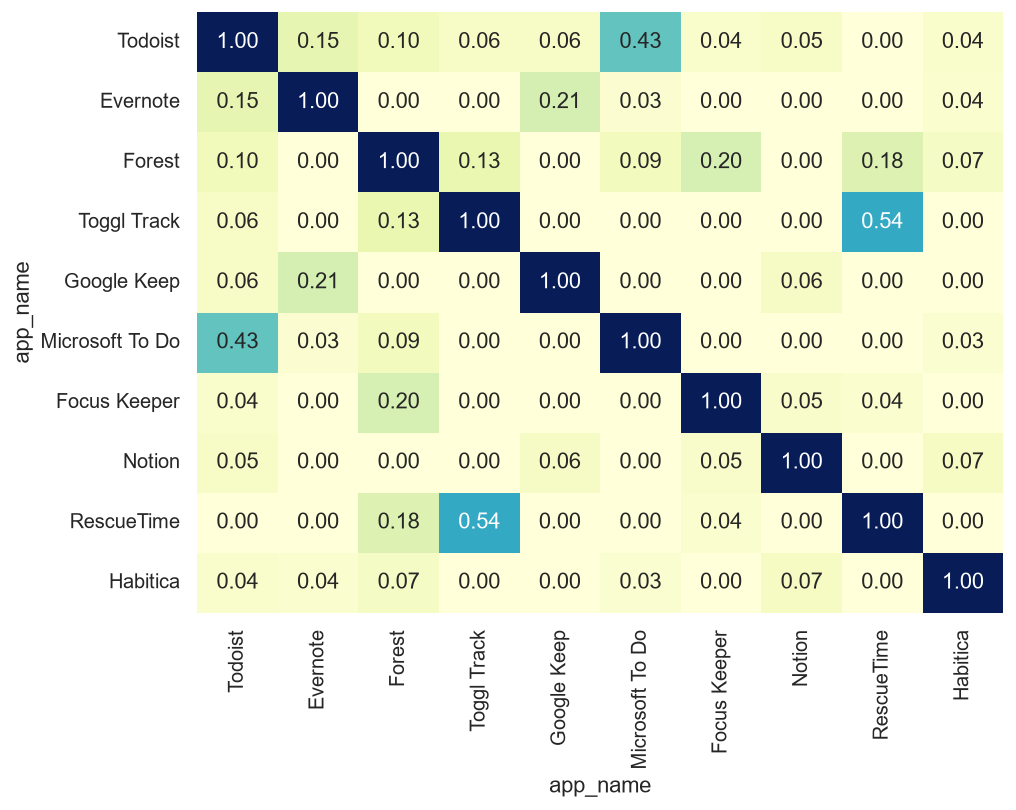

In [6]:
print("URK24CS1021")

plt.figure(figsize=(8, 6))
sns.heatmap(sim_df, annot=True, fmt=".2f", cmap="YlGnBu", cbar=False)
plt.show()

### The recommender

In [7]:
print("URK24CS1021")

def recommend(app_name, n=3):
    # row of similarities, high to low, skip position 0 (the app itself)
    i = apps.index[apps["app_name"] == app_name][0]
    order = sim[i].argsort()[::-1][1:n + 1]
    out = apps.loc[order, ["app_name", "function"]].copy()
    out["similarity"] = sim[i][order].round(3)
    return out.reset_index(drop=True)

recommend("Todoist")

URK24CS1021


,app_name,function,similarity
0,Microsoft To Do,"Task Management, Microsoft Integration",0.433
1,Evernote,"Note-taking, Organization, Sync",0.149
2,Forest,"Focus, Time Management, Gamification",0.100


In [8]:
print("URK24CS1021")

recommend("Forest")

URK24CS1021


,app_name,function,similarity
0,Focus Keeper,"Pomodoro Technique, Focus, Timer",0.201
1,RescueTime,"Automatic Tracking, Analytics, Focus",0.180
2,Toggl Track,"Time Tracking, Analytics, Productivity",0.135


In [9]:
print("URK24CS1021")

recommend("Habitica")

URK24CS1021


,app_name,function,similarity
0,Notion,"All-in-one, Workspace, Collaboration",0.073
1,Forest,"Focus, Time Management, Gamification",0.067
2,Todoist,"Task Management, Organization, Productivity",0.039


### A user who likes more than one app

In [10]:
print("URK24CS1021")

liked = ["Todoist", "Notion"]
idx = apps.index[apps["app_name"].isin(liked)]
taste = sim[idx].mean(axis=0)
taste[idx] = -1  # not the ones they already have
top = taste.argsort()[::-1][:3]
pd.DataFrame({"app": apps.loc[top, "app_name"].values, "score": taste[top].round(3)})

URK24CS1021


,app,score
0,Microsoft To Do,0.216
1,Evernote,0.075
2,Google Keep,0.061
